In [1]:
import sys
import os
from pathlib import Path
import json

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
data_path = Path("books_processed.csv")


def read_csv_fallback(path: Path) -> pd.DataFrame:
    encodings = ["utf-8", "utf-8-sig", "latin1"]
    last_error = None
    for enc in encodings:
        try:
            return pd.read_csv(path, encoding=enc)
        except Exception as exc:
            last_error = exc
    raise last_error


df_raw = read_csv_fallback(data_path)
print("Shape:", df_raw.shape)
print("Columns:", list(df_raw.columns))

df_raw.head(50000)

Shape: (30147, 33)
Columns: ['title', 'description', 'price', 'author', 'category', 'rating', 'thumbnail', 'product_code', 'supplier', 'translator', 'publisher', 'publish_year', 'language', 'weight_grams', 'num_pages', 'book_format', 'source_url', 'category_norm', 'language_norm', 'description_word_count', 'missing_description', 'num_words_in_description', 'series_name', 'volume_number', 'age', 'price_bucket', 'rating_bucket', 'pages_bucket', 'has_translator', 'is_vietnamese', 'doc_id', 'embedding_text', 'bm25_text']


,title,description,price,author,category,rating,thumbnail,product_code,supplier,translator,...,volume_number,age,price_bucket,rating_bucket,pages_bucket,has_translator,is_vietnamese,doc_id,embedding_text,bm25_text
0,"1,2,3,5 Bữa - Nói Tóm Lại Ăn Thế Nào Là Tốt",1 bữa 1 ngày 2 bữa 1 ngày 5 bữa 1 ngày BẠN ĐAN...,79000.0,Woo Won Yang,Y học,5.0,https://cdn1.fahasa.com/media/catalog/product/...,8935280902534,Thái Hà,Nguyệt Minh,...,NaN,-18164.0,mid,high,very_long,True,False,https://www.fahasa.com/1-2-3-5-bua-noi-tom-lai...,"1,2,3,5 Bữa - Nói Tóm Lại Ăn Thế Nào Là Tốt | ...","1,2,3,5 Bữa - Nói Tóm Lại Ăn Thế Nào Là Tốt | ..."
1,Hình Dán Sticker Và Tô Màu - Tập 6,Hình Dán Sticker Và Tô Màu - Tập 6 Hình Dán St...,18000.0,Trần Ngọc Bảo Hân,"Tô màu, luyện chữ",5.0,https://cdn1.fahasa.com/media/catalog/product/...,8935072958428,Cty Văn Hóa Nhân Văn,NaN,...,6.0,-18224.0,low,high,medium,False,False,https://www.fahasa.com/1-2-4-14-153-637350.html,Hình Dán Sticker Và Tô Màu - Tập 6 | Trần Ngọc...,Hình Dán Sticker Và Tô Màu - Tập 6 | Trần Ngọc...
2,Hình Dán Sticker Và Tô Màu - Tập 10,Hình Dán Sticker Và Tô Màu - Tập 10 Hình Dán S...,18000.0,Trần Ngọc Bảo Hân,"Tô màu, luyện chữ",5.0,https://cdn1.fahasa.com/media/catalog/product/...,8935072958466,Cty Văn Hóa Nhân Văn,NaN,...,10.0,-18224.0,low,high,medium,False,False,https://www.fahasa.com/1-2-4-14-153-637354.html,Hình Dán Sticker Và Tô Màu - Tập 10 | Trần Ngọ...,Hình Dán Sticker Và Tô Màu - Tập 10 | Trần Ngọ...
3,Hình Dán Sticker Và Tô Màu - Tập 1,Hình Dán Sticker Và Tô Màu - Tập 1 Hình Dán St...,18000.0,Trần Ngọc Bảo Hân,"Tô màu, luyện chữ",5.0,https://cdn1.fahasa.com/media/catalog/product/...,8935072958374,Cty Văn Hóa Nhân Văn,NaN,...,1.0,-18224.0,low,high,medium,False,False,https://www.fahasa.com/1-2-4-14-153.html,Hình Dán Sticker Và Tô Màu - Tập 1 | Trần Ngọc...,Hình Dán Sticker Và Tô Màu - Tập 1 | Trần Ngọc...
4,Khám Phá Thế Giới Khủng Long - Những Bí Ẩn Thờ...,Khám Phá Thế Giới Khủng Long - Những Bí Ẩn Thờ...,91000.0,Jackie Nguyễn,Tạp Chí Thiếu Nhi,5.0,https://cdn1.fahasa.com/media/catalog/product/...,8936065773356,CÔNG TY TNHH IN THƯƠNG MẠI TUẤN VIỆT,NaN,...,NaN,-18214.0,mid,high,very_long,False,False,https://www.fahasa.com/1-2-4-14-6238.html,Khám Phá Thế Giới Khủng Long - Những Bí Ẩn Thờ...,Khám Phá Thế Giới Khủng Long - Những Bí Ẩn Thờ...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30142,Itto - Cơn Lốc Sân Cỏ - Tập 13 - Quyết Thắng T...,Itto - Cơn Lốc Sân Cỏ - Tập 13 - Quyết Thắng T...,23500.0,Motoki Monma,Manga Khác,5.0,https://cdn1.fahasa.com/media/catalog/product/...,8935352614129,Nhà Xuất Bản Kim Đồng,Song Tâm Quyên,...,13.0,-18214.0,low,high,very_long,True,False,https://www.fahasa.com/itto-con-loc-san-co-tap...,Itto - Cơn Lốc Sân Cỏ - Tập 13 - Quyết Thắng T...,Itto - Cơn Lốc Sân Cỏ - Tập 13 - Quyết Thắng T...
30143,Kĩ Năng Giao Tiếp - Dành Cho Bé 2-6 Tuổi - Lời...,Khả năng giao tiếp hạn chế sẽ tạo nên những tổ...,13500.0,"Hiếu Minh, Nguyễn Thanh Hà",Sách Tranh Kỹ Năng Sốn...,5.0,https://cdn1.fahasa.com/media/catalog/product/...,8935244823813,Nhà Xuất Bản Kim Đồng,NaN,...,NaN,-18164.0,low,high,medium,False,False,https://www.fahasa.com/ki-nang-giao-tiep-danh-...,Kĩ Năng Giao Tiếp - Dành Cho Bé 2-6 Tuổi - Lời...,Kĩ Năng Giao Tiếp - Dành Cho Bé 2-6 Tuổi - Lời...
30144,Tô Màu Hoàng Tử Ếch - Thế Giới Robot,Sự kết hợp của khả năng tập trung và sáng tạo ...,12500.0,Ngọc Hà,"Tô màu, luyện chữ",5.0,https://cdn1.fahasa.com/media/catalog/product/...,8935095625659,Huy Hoang Bookstore,NaN,...,NaN,-18154.0,low,high,medium,False,False,https://www.fahasa.com/to-mau-hoang-tu-ech-the...,Tô Màu Hoàng Tử Ếch - Thế Giới Robot | Ngọc Hà...,Tô Màu Hoàng Tử Ếch - Thế Giới Robot | Ngọc Hà...
30145,Ứng Dụng Tâm Lý Học NLP - Kỹ Thuật NLP Chốn Vă...,Ứng Dụng Tâm Lý Học NLP - Kỹ Thuật NLP Chốn Vă...,76500.0,Dianne Lowther,Tâm lý,5.0,https://cdn1.fahasa.com/media/catalog/product/...,8935074131645,Cty Văn Hóa Văn Lang,Bội Ngọc,...,NaN,-18204.0,mid,high,very_long,True,F

In [3]:
for column in ["category", "rating","rating_bucket", "source_url", "num_words_in_description",  "age", "has_translator", "is_vietnamese", "doc_id","embedding_text","bm25_text"]:
    if column in df_raw.columns:
        df_raw.drop(columns=[column], inplace=True)


df_raw.head(50000)

,title,description,price,author,thumbnail,product_code,supplier,translator,publisher,publish_year,...,num_pages,book_format,category_norm,language_norm,description_word_count,missing_description,series_name,volume_number,price_bucket,pages_bucket
0,"1,2,3,5 Bữa - Nói Tóm Lại Ăn Thế Nào Là Tốt",1 bữa 1 ngày 2 bữa 1 ngày 5 bữa 1 ngày BẠN ĐAN...,79000.0,Woo Won Yang,https://cdn1.fahasa.com/media/catalog/product/...,8935280902534,Thái Hà,Nguyệt Minh,NXB Thế Giới,20190.0,...,2690.0,Bìa Mềm,health,other,587,False,"1,2,3,5 Bữa - Nói Tóm Lại Ăn Thế Nào Là Tốt",NaN,mid,very_long
1,Hình Dán Sticker Và Tô Màu - Tập 6,Hình Dán Sticker Và Tô Màu - Tập 6 Hình Dán St...,18000.0,Trần Ngọc Bảo Hân,https://cdn1.fahasa.com/media/catalog/product/...,8935072958428,Cty Văn Hóa Nhân Văn,NaN,Thanh Hóa,20250.0,...,200.0,Bìa Mềm,children_activity,other,173,False,Hình Dán Sticker Và Tô Màu,6.0,low,medium
2,Hình Dán Sticker Và Tô Màu - Tập 10,Hình Dán Sticker Và Tô Màu - Tập 10 Hình Dán S...,18000.0,Trần Ngọc Bảo Hân,https://cdn1.fahasa.com/media/catalog/product/...,8935072958466,Cty Văn Hóa Nhân Văn,NaN,Thanh Hóa,20250.0,...,200.0,Bìa Mềm,children_activity,other,173,False,Hình Dán Sticker Và Tô Màu,10.0,low,medium
3,Hình Dán Sticker Và Tô Màu - Tập 1,Hình Dán Sticker Và Tô Màu - Tập 1 Hình Dán St...,18000.0,Trần Ngọc Bảo Hân,https://cdn1.fahasa.com/media/catalog/product/...,8935072958374,Cty Văn Hóa Nhân Văn,NaN,Thanh Hóa,20250.0,...,200.0,Bìa Mềm,children_activity,other,173,False,Hình Dán Sticker Và Tô Màu,1.0,low,medium
4,Khám Phá Thế Giới Khủng Long - Những Bí Ẩn Thờ...,Khám Phá Thế Giới Khủng Long - Những Bí Ẩn Thờ...,91000.0,Jackie Nguyễn,https://cdn1.fahasa.com/media/catalog/product/...,8936065773356,CÔNG TY TNHH IN THƯƠNG MẠI TUẤN VIỆT,NaN,Đồng Nai,20240.0,...,880.0,Bìa Mềm,children_magazine,other,284,False,Khám Phá Thế Giới Khủng Long - Những Bí Ẩn Thờ...,NaN,mid,very_long
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30142,Itto - Cơn Lốc Sân Cỏ - Tập 13 - Quyết Thắng T...,Itto - Cơn Lốc Sân Cỏ - Tập 13 - Quyết Thắng T...,23500.0,Motoki Monma,https://cdn1.fahasa.com/media/catalog/product/...,8935352614129,Nhà Xuất Bản Kim Đồng,Song Tâm Quyên,Kim Đồng,20240.0,...,1920.0,Bìa Mềm,manga,other,71,False,Itto - Cơn Lốc Sân Cỏ,13.0,low,very_long
30143,Kĩ Năng Giao Tiếp - Dành Cho Bé 2-6 Tuổi - Lời...,Khả năng giao tiếp hạn chế sẽ tạo nên những tổ...,13500.0,"Hiếu Minh, Nguyễn Thanh Hà",https://cdn1.fahasa.com/media/catalog/product/...,8935244823813,Nhà Xuất Bản Kim Đồng,NaN,NXB Kim Đồng,20190.0,...,200.0,Bìa Mềm,children_skill,other,257,False,Kĩ Năng Giao Tiếp - Dành Cho Bé 2-6 Tuổi - Lời...,NaN,low,medium
30144,Tô Màu Hoàng Tử Ếch - Thế Giới Robot,Sự kết hợp của khả năng tập trung và sáng tạo ...,12500.0,Ngọc Hà,https://cdn1.fahasa.com/media/catalog/product/...,8935095625659,Huy Hoang Bookstore,NaN,NXB Mỹ Thuật,20180.0,...,240.0,Bìa Mềm,children_activity,other,236,False,Tô Màu Hoàng Tử Ếch - Thế Giới Robot,NaN,low,medium
30145,Ứng Dụng Tâm Lý Học NLP - Kỹ Thuật NLP Chốn Vă...,Ứng Dụng Tâm Lý Học NLP - Kỹ Thuật NLP Chốn Vă...,76500.0,Dianne Lowther,https://cdn1.fahasa.com/media/catalog/product/...,8935074131645,Cty Văn Hóa Văn Lang,Bội Ngọc,Hồng Đức,20230.0,...,2400.0,Bìa Mềm,psychology,other,179,False,Ứng Dụng Tâm Lý Học NLP - Kỹ Thuật NLP Chốn Vă...,NaN,mid,very_long


In [4]:
if "product_code" in df_raw.columns:
    dup_product_code = df_raw.duplicated(subset=["product_code"]).sum()
    print(f"Duplicate product codes: {dup_product_code}")
    if dup_product_code > 0:
        print("Sample duplicate product codes:")
        print(df_raw[df_raw.duplicated(subset=["product_code"], keep=False)]["product_code"].value_counts().head())
        # Remove duplicate rows based on 'product_code'
        df_raw = df_raw.drop_duplicates(subset=["product_code"], keep="first")

Duplicate product codes: 0


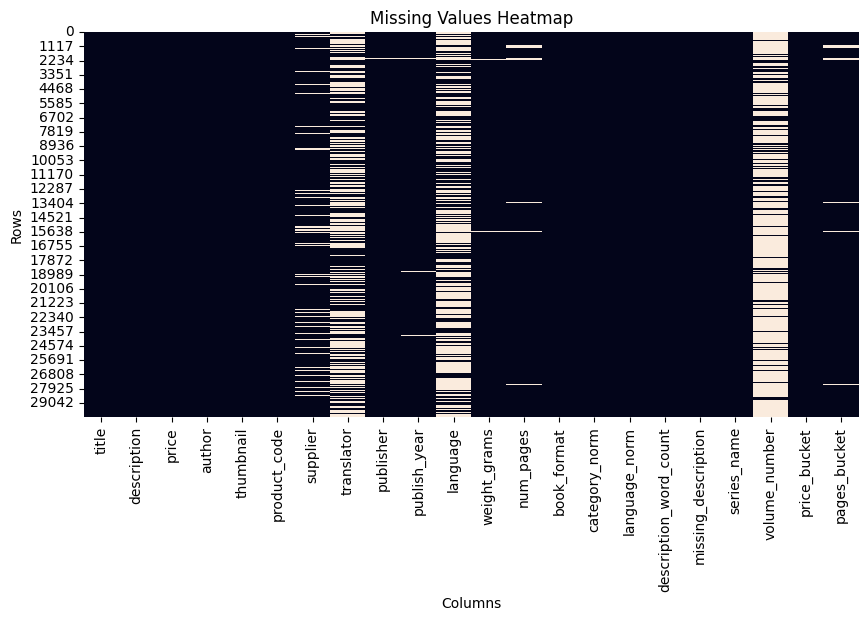

In [5]:
plt.figure(figsize=(10, 5))
sns.heatmap(df_raw.isna(), cbar=False)
plt.title("Missing Values Heatmap")
plt.xlabel("Columns")
plt.ylabel("Rows")
plt.show()

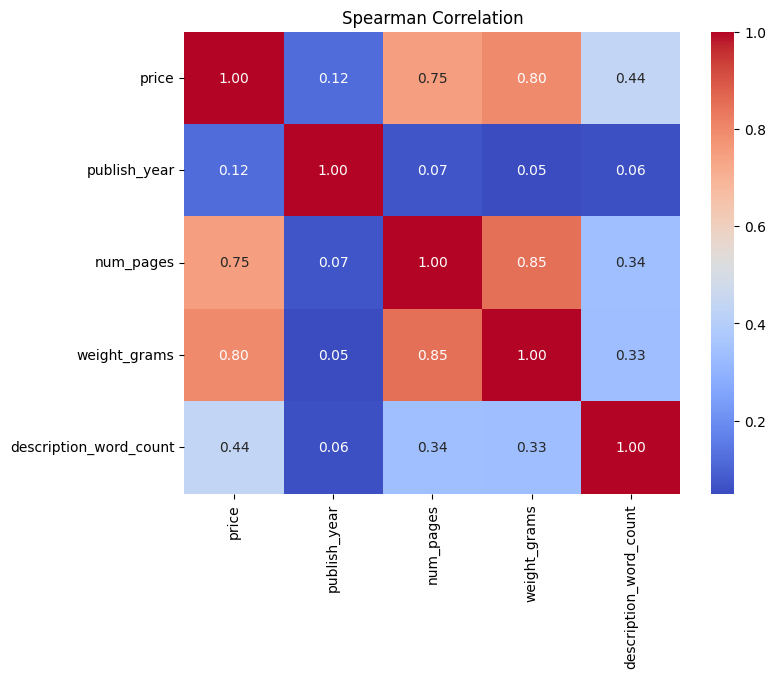

In [6]:
corr_cols = [c for c in ["price", "publish_year", "num_pages", "weight_grams", "description_word_count"] if c in df_raw.columns]

if len(corr_cols) >= 2:
    corr = df_raw[corr_cols].corr(method="spearman")
    plt.figure(figsize=(8, 6))
    sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
    plt.title("Spearman Correlation")
    plt.show()
else:
    print("Not enough numeric columns for correlation.")

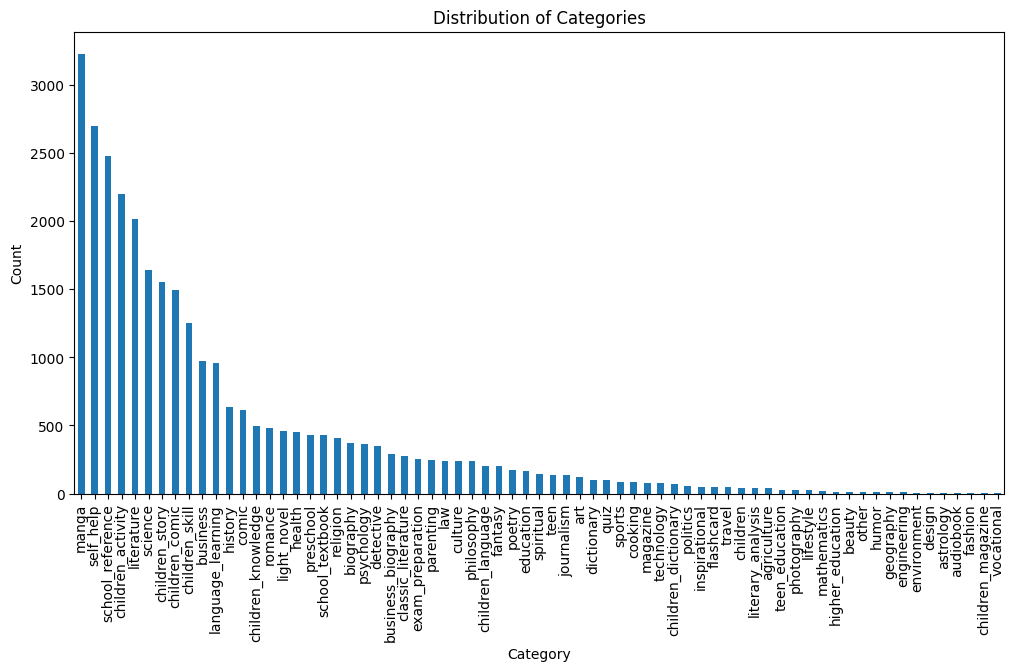

category_norm
manga                3229
self_help            2699
school_reference     2481
children_activity    2195
literature           2012
                     ... 
astrology               5
audiobook               4
fashion                 4
children_magazine       1
vocational              1
Name: count, Length: 69, dtype: int64

In [7]:
# category
category_counts = df_raw["category_norm"].value_counts()
plt.figure(figsize=(12, 6))
category_counts.plot(kind="bar")
plt.title("Distribution of Categories")
plt.xlabel("Category")
plt.ylabel("Count")
plt.show()
category_counts

In [8]:
# show category counts as a dictionary
category_counts_dict = category_counts.to_dict()
print(category_counts_dict)

{'manga': 3229, 'self_help': 2699, 'school_reference': 2481, 'children_activity': 2195, 'literature': 2012, 'science': 1644, 'children_story': 1551, 'children_comic': 1491, 'children_skill': 1253, 'business': 976, 'language_learning': 961, 'history': 637, 'comic': 610, 'children_knowledge': 496, 'romance': 485, 'light_novel': 458, 'health': 449, 'preschool': 432, 'school_textbook': 428, 'religion': 409, 'biography': 373, 'psychology': 366, 'detective': 346, 'business_biography': 287, 'classic_literature': 278, 'exam_preparation': 251, 'parenting': 247, 'law': 242, 'culture': 239, 'philosophy': 238, 'children_language': 201, 'fantasy': 201, 'poetry': 171, 'education': 165, 'spiritual': 142, 'teen': 135, 'journalism': 134, 'art': 124, 'dictionary': 100, 'quiz': 100, 'sports': 87, 'cooking': 82, 'magazine': 76, 'technology': 76, 'children_dictionary': 70, 'politics': 55, 'inspirational': 51, 'flashcard': 50, 'travel': 49, 'children': 42, 'literary_analysis': 39, 'agriculture': 38, 'teen_e

In [9]:
df_raw.columns

Index(['title', 'description', 'price', 'author', 'thumbnail', 'product_code',
       'supplier', 'translator', 'publisher', 'publish_year', 'language',
       'weight_grams', 'num_pages', 'book_format', 'category_norm',
       'language_norm', 'description_word_count', 'missing_description',
       'series_name', 'volume_number', 'price_bucket', 'pages_bucket'],
      dtype='object')

In [10]:
# 1. Sao chép dữ liệu gốc
df = df_raw.copy()

# 2. Loại bỏ sách audiobook
df = df[df["category_norm"] != "audiobook"].copy()

# 3. Kiểm tra kết quả
print("Số mẫu sau khi loại audiobook:", len(df))
print("Số nhãn còn lại:", df["category_norm"].nunique())
print("Số sách audiobook còn lại:",
      (df["category_norm"] == "audiobook").sum())

Số mẫu sau khi loại audiobook: 30143
Số nhãn còn lại: 68
Số sách audiobook còn lại: 0


In [11]:

import pandas as pd


label_map = {
    "literary_analysis": "literature",
    "agriculture": "science_applied",
    "teen_education": "education",
    "higher_education": "education",
    "photography": "art_visual",
    "beauty": "lifestyle",
    "engineering": "technology",
    "environment": "science",
    "design": "art_visual",
    "astrology": "spiritual",
    "fashion": "lifestyle",
    "vocational": "education",
    "children_magazine": "children_general",
    "children": "children_general",
}

df["category_norm"] = (
    df["category_norm"]
    .map(label_map)
    .fillna(df["category_norm"])
)

# Chỉ là mapping sơ bộ; kiểm tra các nhãn còn ít mẫu
counts_after = df["category_norm"].value_counts()

print("Số nhãn sau chuẩn hóa:", df["category_norm"].nunique())
print("\nCác nhãn dưới 50 mẫu:")
print(counts_after[counts_after < 50])

print("\nPhân phối nhãn mới:")
print(counts_after)

Số nhãn sau chuẩn hóa: 57

Các nhãn dưới 50 mẫu:
category_norm
travel              49
children_general    43
lifestyle           42
science_applied     38
art_visual          31
mathematics         17
other               13
humor               13
geography           12
Name: count, dtype: int64

Phân phối nhãn mới:
category_norm
manga                  3229
self_help              2699
school_reference       2481
children_activity      2195
literature             2051
science                1650
children_story         1551
children_comic         1491
children_skill         1253
business                976
language_learning       961
history                 637
comic                   610
children_knowledge      496
romance                 485
light_novel             458
health                  449
preschool               432
school_textbook         428
religion                409
biography               373
psychology              366
detective               346
business_biography      2

In [12]:

import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Copy dữ liệu gốc, không sửa trực tiếp df_raw

LABEL_COL = "category_norm"
TEXT_COLS = ["title", "description"]

# 2. Kiểm tra dữ liệu cơ bản
print("Shape ban đầu:", df.shape)
print("Số nhãn:", df[LABEL_COL].nunique())
print("\nTop nhãn:")
print(df[LABEL_COL].value_counts().head(20))

# 3. Chuẩn hóa nhãn và văn bản
df = df.dropna(subset=[LABEL_COL]).copy()
df[LABEL_COL] = df[LABEL_COL].astype(str).str.strip()

for col in TEXT_COLS:
    df[col] = df[col].fillna("").astype(str).str.strip()

# Loại bản ghi không có cả tiêu đề lẫn mô tả
has_text = df[TEXT_COLS].ne("").any(axis=1)
df = df[has_text].copy()

# 4. Kiểm tra trùng lặp trước khi xóa
# Không xóa tự động nếu cùng nội dung nhưng khác nhãn
df["_text_key"] = (
    df[TEXT_COLS]
    .agg(" ".join, axis=1)
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

conflicts = (
    df.groupby("_text_key")[LABEL_COL]
    .nunique()
    .gt(1)
    .sum()
)
print("Số nhóm nội dung có nhãn xung đột:", conflicts)

# Chỉ loại trùng hoàn toàn về nội dung và nhãn
df = df.drop_duplicates(
    subset=["_text_key", LABEL_COL]
).drop(columns="_text_key")

df = df.reset_index(drop=True)

# 5. Phân tầng cho các nhãn có ít nhất 10 mẫu
counts = df[LABEL_COL].value_counts()
common_labels = counts[counts >= 10].index

common = df[df[LABEL_COL].isin(common_labels)].copy()
rare = df[~df[LABEL_COL].isin(common_labels)].copy()

# 6. Chia 80% train, 10% validation, 10% test
train_common, holdout = train_test_split(
    common,
    test_size=0.20,
    random_state=42,
    stratify=common[LABEL_COL]
)

val, test = train_test_split(
    holdout,
    test_size=0.50,
    random_state=42,
    stratify=holdout[LABEL_COL]
)

# Nhãn hiếm được giữ ở train để tránh lỗi stratify
train = pd.concat([train_common, rare], ignore_index=True)

# Xáo trộn tập train
train = train.sample(frac=1, random_state=42).reset_index(drop=True)

# 7. Lưu các tập dữ liệu
train.to_csv("train.csv", index=False, encoding="utf-8-sig")
val.to_csv("validation.csv", index=False, encoding="utf-8-sig")
test.to_csv("test.csv", index=False, encoding="utf-8-sig")

print("\nTrain:", train.shape)
print("Validation:", val.shape)
print("Test:", test.shape)

Shape ban đầu: (30143, 22)
Số nhãn: 57

Top nhãn:
category_norm
manga                 3229
self_help             2699
school_reference      2481
children_activity     2195
literature            2051
science               1650
children_story        1551
children_comic        1491
children_skill        1253
business               976
language_learning      961
history                637
comic                  610
children_knowledge     496
romance                485
light_novel            458
health                 449
preschool              432
school_textbook        428
religion               409
Name: count, dtype: int64
Số nhóm nội dung có nhãn xung đột: 0

Train: (24091, 22)
Validation: (3011, 22)
Test: (3012, 22)


In [13]:

for split_name, split_df in [
    ("train", train),
    ("validation", val),
    ("test", test),
]:
    print(f"\n--- {split_name} ---")
    print("Số mẫu:", len(split_df))
    print("Số nhãn:", split_df["category_norm"].nunique())
    print(split_df["category_norm"].value_counts().head(10))


--- train ---
Số mẫu: 24091
Số nhãn: 57
category_norm
manga                2581
self_help            2156
school_reference     1980
children_activity    1753
literature           1640
science              1319
children_story       1241
children_comic       1193
children_skill       1001
business              781
Name: count, dtype: int64

--- validation ---
Số mẫu: 3011
Số nhãn: 57
category_norm
manga                322
self_help            269
school_reference     247
children_activity    219
literature           205
science              165
children_story       155
children_comic       149
children_skill       125
business              97
Name: count, dtype: int64

--- test ---
Số mẫu: 3012
Số nhãn: 57
category_norm
manga                323
self_help            270
school_reference     248
children_activity    220
literature           205
science              165
children_story       155
children_comic       149
children_skill       126
business              98
Name: count, dtype: i

In [14]:

train_labels = set(train["category_norm"].dropna().unique())
val_labels = set(val["category_norm"].dropna().unique())
test_labels = set(test["category_norm"].dropna().unique())

print("Chỉ có trong train:")
print(sorted(train_labels - val_labels))

print("\nKhông có trong test:")
print(sorted(train_labels - test_labels))

print("\nSố mẫu của các nhãn không có trong validation:")
print(
    train.loc[
        train["category_norm"].isin(train_labels - val_labels),
        "category_norm"
    ].value_counts()
)

Chỉ có trong train:
[]

Không có trong test:
[]

Số mẫu của các nhãn không có trong validation:
Series([], Name: count, dtype: int64)
